# 03. Финальная мультимодальная модель Efficient HADES

В предыдущем ноутбуке мы не пытались выиграть соревнование моделей любой ценой. Там была более простая задача: проверить, что сам протокол данных работает честно, что split не смешивает смысл, что разные targets действительно ведут себя по-разному, а baseline не разваливается на первом же сравнении.

Здесь начинается следующий слой работы: берем уже проверенный pipeline и обучаем финальную fused-модель. Ее смысл не в том, чтобы заменить все простые методы на нейросеть из принципа. Смысл другой: получить единый мультимодальный контур, который одновременно видит логи, KPI, несколько горизонтов предупреждения и может быть перенесен в dashboard как один воспроизводимый bundle.

Полное обучение в этом ноутбуке оставлено как часть исследования, но по умолчанию выключено: текущая машина не предназначена для длинного CUDA-запуска. На обучающей машине достаточно включить флаг `RUN_FULL_TRAINING = True` или выполнить напечатанную команду. Все аналитические ячейки ниже умеют читать уже готовые артефакты из `dashboard/artifacts/model/protocol_fixed_efficient_hades`.


In [1]:
from __future__ import annotations

import json
import os
import shlex
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import auc, precision_recall_curve, roc_curve

sns.set_theme(
    context="notebook",
    style="whitegrid",
    palette="Set2",
    rc={
        "figure.figsize": (11, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
        "font.family": "DejaVu Sans",
    },
)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

PROJECT_ROOT = Path.cwd()
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
CONTRACT_PATH = ARTIFACT_DIR / "contract" / "strict_intensity_contract.csv.gz"
BASELINE_DIR = ARTIFACT_DIR / "reports" / "protocol_fixed_baselines"
RUN_ROOT = ARTIFACT_DIR / "model_runs" / "protocol_fixed_hades"
RUN_ID = "final_protocol_fixed_hades"
RUN_DIR = RUN_ROOT / RUN_ID
MODEL_OUT_DIR = ARTIFACT_DIR / "model" / "protocol_fixed_efficient_hades"
BUNDLE_DIR = ARTIFACT_DIR / "bundle"

FINAL_CONFIG = {
    "run_id": RUN_ID,
    "device": "cuda",
    "split_protocol": "stratified_by_workload",
    "variant": "modern_metric",
    "seed": 43,
    "monitor_target": "horizon_60s",
    "alert_target": "horizon_60s",
    "normalization": "workload_norm",
    "metric_feature_mode": "raw_plus_deviation",
    "epochs": 30,
    "batch_size": 128,
    "patience": 8,
    "fp_budget": 0.10,
    "quantization": "dynamic",
}

TARGET_ORDER = [
    "y_warning",
    "y_anomaly",
    "y_risk",
    "horizon_30s",
    "horizon_60s",
    "horizon_120s",
    "horizon_300s",
]
TARGET_LABELS = {
    "y_warning": "Предупреждение",
    "y_anomaly": "Аномалия",
    "y_risk": "Риск",
    "horizon_30s": "Горизонт 30с",
    "horizon_60s": "Горизонт 60с",
    "horizon_120s": "Горизонт 120с",
    "horizon_300s": "Горизонт 300с",
}
METRIC_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "average_precision": "AP",
    "roc_auc": "ROC-AUC",
}

def safe_read_csv(path: Path, **kwargs) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    try:
        return pd.read_csv(path, **kwargs)
    except Exception as exc:
        print(f"Не удалось прочитать {path}: {exc}")
        return pd.DataFrame()

def safe_read_json(path: Path):
    if not path.exists():
        return None
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"Не удалось прочитать {path}: {exc}")
        return None

def file_status(paths: dict[str, Path]) -> pd.DataFrame:
    rows = []
    for name, path in paths.items():
        rows.append(
            {
                "артефакт": name,
                "найден": path.exists(),
                "размер_кб": round(path.stat().st_size / 1024, 1) if path.exists() else np.nan,
                "путь": str(path.relative_to(PROJECT_ROOT)) if path.exists() else str(path.relative_to(PROJECT_ROOT)),
            }
        )
    return pd.DataFrame(rows)

def choose_result_dir() -> Path:
    promoted_metrics = MODEL_OUT_DIR / "comparison_metrics.csv"
    fresh_metrics = RUN_DIR / "comparison_metrics.csv"
    if promoted_metrics.exists():
        return MODEL_OUT_DIR
    if fresh_metrics.exists():
        return RUN_DIR
    return MODEL_OUT_DIR

RESULT_DIR = choose_result_dir()

def filter_final_metrics(df: pd.DataFrame, threshold_policy: str = "validation_best_f1") -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    out = df.copy()
    numeric_cols = [
        "seed",
        "precision",
        "recall",
        "f1",
        "average_precision",
        "roc_auc",
        "false_positives",
        "missed_anomalies",
        "threshold",
        "torch_latency_ms_per_sample",
    ]
    for col in numeric_cols:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    mask = (
        out["split_protocol"].astype(str).eq(FINAL_CONFIG["split_protocol"])
        & out["variant"].astype(str).eq(FINAL_CONFIG["variant"])
        & out["seed"].eq(FINAL_CONFIG["seed"])
        & out["runtime"].astype(str).eq("torch_fp32")
        & out["split"].astype(str).eq("test")
        & out["threshold_policy"].astype(str).eq(threshold_policy)
    )
    return out.loc[mask].copy()

def best_baseline_metrics(df: pd.DataFrame, threshold_policy: str = "validation_best_f1") -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    out = df.copy()
    for col in ["precision", "recall", "f1", "average_precision", "roc_auc", "false_positives", "missed_anomalies"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    mask = (
        out["split_protocol"].astype(str).eq(FINAL_CONFIG["split_protocol"])
        & out["split"].astype(str).eq("test")
        & out["threshold_policy"].astype(str).eq(threshold_policy)
    )
    out = out.loc[mask].sort_values(["target", "f1"], ascending=[True, False])
    return out.groupby("target", as_index=False).head(1)

def run_command(command: list[str]) -> None:
    print(" ".join(shlex.quote(str(part)) for part in command))
    completed = subprocess.run(command, cwd=PROJECT_ROOT)
    if completed.returncode != 0:
        raise RuntimeError(f"Команда завершилась с кодом {completed.returncode}")

def show_note(text: str) -> None:
    display(Markdown(text))


## Что здесь проверяем

После baseline остается нормальный инженерный вопрос: дает ли мультимодальная модель что-то сверх простой проверки данных? Для ВКР здесь важны не только числа в одной строке, а весь контур: как модель смотрит на окно, как она учится, где ошибается, как ее score превращается в alert-layer и что именно попадет в dashboard.

Поэтому я смотрю на модель в четырех плоскостях:

1. Архитектура: действительно ли сохраняется HADES-путь `логи + метрики + cross-modal interaction`.
2. Обучение: есть ли понятная динамика по эпохам, а не случайный удачный checkpoint.
3. Сравнение: выигрывает ли финальная модель у простого baseline там, где это важно для раннего предупреждения.
4. Эксплуатация: можно ли превратить score в более спокойный alert-layer без подмены смысла.


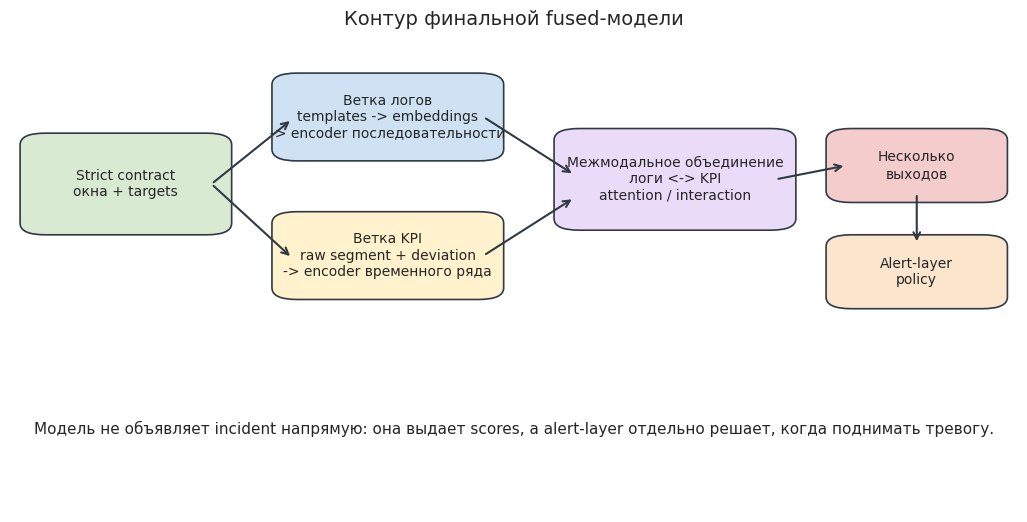

In [2]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 6))
ax.axis("off")

boxes = [
    (0.03, 0.62, 0.17, 0.18, "Strict contract\nокна + targets", "#d9ead3"),
    (0.28, 0.78, 0.19, 0.15, "Ветка логов\ntemplates -> embeddings\n-> encoder последовательности", "#cfe2f3"),
    (0.28, 0.48, 0.19, 0.15, "Ветка KPI\nraw segment + deviation\n-> encoder временного ряда", "#fff2cc"),
    (0.56, 0.63, 0.20, 0.18, "Межмодальное объединение\nлоги <-> KPI\nattention / interaction", "#eadcf8"),
    (0.83, 0.69, 0.14, 0.12, "Несколько\nвыходов", "#f4cccc"),
    (0.83, 0.46, 0.14, 0.12, "Alert-layer\npolicy", "#fce5cd"),
]

for x, y, w, h, text, color in boxes:
    patch = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.2,
        edgecolor="#2f3a45",
        facecolor=color,
        transform=ax.transAxes,
    )
    ax.add_patch(patch)
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10, transform=ax.transAxes)

arrows = [
    ((0.20, 0.71), (0.28, 0.85)),
    ((0.20, 0.71), (0.28, 0.55)),
    ((0.47, 0.855), (0.56, 0.73)),
    ((0.47, 0.555), (0.56, 0.68)),
    ((0.76, 0.72), (0.83, 0.75)),
    ((0.90, 0.69), (0.90, 0.58)),
]
for start, end in arrows:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        xycoords=ax.transAxes,
        arrowprops=dict(arrowstyle="->", lw=1.5, color="#2f3a45"),
    )

ax.text(
    0.50,
    0.18,
    "Модель не объявляет incident напрямую: она выдает scores, а alert-layer отдельно решает, когда поднимать тревогу.",
    ha="center",
    va="center",
    fontsize=11,
    transform=ax.transAxes,
)
ax.set_title("Контур финальной fused-модели", pad=18)
plt.show()


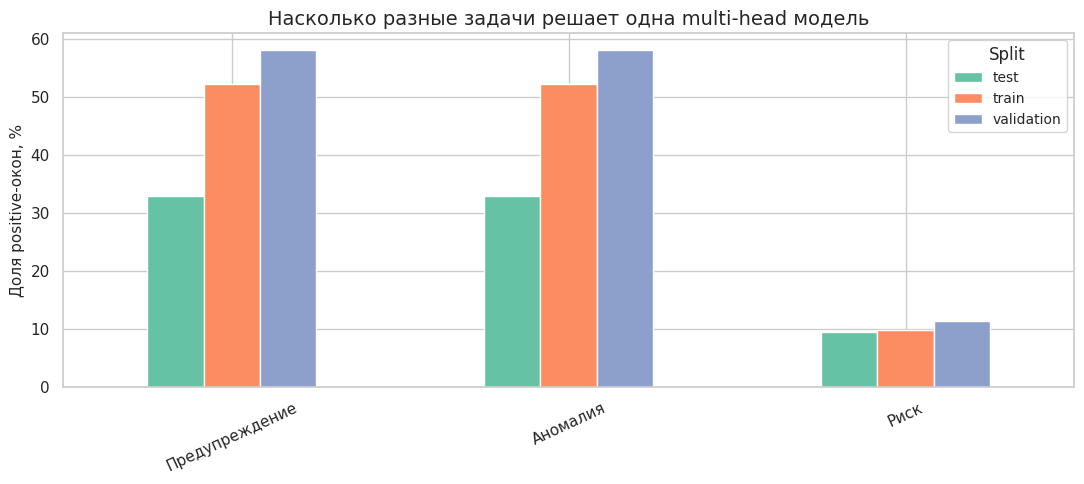

split,target,test,train,validation
0,Предупреждение,33.0,52.2,58.1
1,Аномалия,33.0,52.2,58.1
2,Риск,9.4,9.8,11.3


In [3]:
contract = safe_read_csv(CONTRACT_PATH)
target_cols = [c for c in TARGET_ORDER if c in contract.columns]

if contract.empty:
    show_note("Contract не найден. Сначала нужно выполнить `python -m dashboard.pipeline.build_contract --raw-data raw_data`.")
else:
    prevalence = (
        contract.groupby("split")[target_cols]
        .mean()
        .T
        .reindex(target_cols)
        .rename(index=TARGET_LABELS)
        * 100
    )
    fig, ax = plt.subplots(figsize=(11, 5))
    prevalence.plot(kind="bar", ax=ax, color=sns.color_palette("Set2", n_colors=max(1, prevalence.shape[1])))
    ax.set_title("Насколько разные задачи решает одна multi-head модель")
    ax.set_xlabel("")
    ax.set_ylabel("Доля positive-окон, %")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title="Split")
    plt.tight_layout()
    plt.show()

    display(
        prevalence.round(1)
        .reset_index()
        .rename(columns={"index": "target"})
        .style.format(precision=1)
    )


На этом графике видно, почему финальная модель обучается как multi-head, а не как один общий бинарный классификатор. `horizon_300s` плотнее и спокойнее: положительных окон много, поэтому его легче поймать. `horizon_60s` уже ближе к реальному раннему предупреждению, но сигнал там шумнее. `horizon_30s` и `y_risk` выглядят как отдельная короткая задача: положительных окон мало, и обычный F1 быстро становится нервным.

Для 03 это важная отправная точка: мы не ждем, что все heads будут иметь одинаковые метрики. Мы смотрим, где модель дает полезное раннее предупреждение, а где задача сама по себе остается пограничной.


## Конфигурация финального запуска

Здесь фиксируется один маршрут, без перебора гипотез внутри ноутбука. Это важно для воспроизводимости: 03 должен быть не складом экспериментов, а местом, где финальная модель обучается и затем сравнивается с baseline из 02.

Основной обучающий target выбран `horizon_60s`: он ближе к раннему предупреждению, чем 120/300 секунд, но еще не такой разреженный, как 30 секунд. При этом модель все равно обучает все обязательные heads, чтобы dashboard мог показывать несколько уровней риска.


In [4]:
train_command = [
    sys.executable,
    "-m",
    "dashboard.training.final_model",
    "--run-id",
    FINAL_CONFIG["run_id"],
    "--device",
    FINAL_CONFIG["device"],
    "--run-root",
    str(RUN_ROOT),
    "--contract-path",
    str(CONTRACT_PATH),
    "--model-out-dir",
    str(MODEL_OUT_DIR),
    "--bundle-out-dir",
    str(BUNDLE_DIR),
    "--split-protocol",
    FINAL_CONFIG["split_protocol"],
    "--variant",
    FINAL_CONFIG["variant"],
    "--seed",
    str(FINAL_CONFIG["seed"]),
    "--monitor-target",
    FINAL_CONFIG["monitor_target"],
    "--alert-target",
    FINAL_CONFIG["alert_target"],
    "--normalization",
    FINAL_CONFIG["normalization"],
    "--metric-feature-mode",
    FINAL_CONFIG["metric_feature_mode"],
    "--epochs",
    str(FINAL_CONFIG["epochs"]),
    "--batch-size",
    str(FINAL_CONFIG["batch_size"]),
    "--patience",
    str(FINAL_CONFIG["patience"]),
    "--fp-budget",
    str(FINAL_CONFIG["fp_budget"]),
    "--quantization",
    FINAL_CONFIG["quantization"],
]

cfg = pd.DataFrame({"параметр": list(FINAL_CONFIG.keys()), "значение": list(FINAL_CONFIG.values())})
display(cfg)

powershell_command = " ".join(shlex.quote(str(part)) for part in train_command)
print("Команда для CUDA-машины:")
print(powershell_command)


,параметр,значение
0,run_id,final_protocol_fixed_hades
1,device,cuda
2,split_protocol,stratified_by_workload
3,variant,modern_metric
4,seed,43
5,monitor_target,horizon_60s
6,alert_target,horizon_60s
7,normalization,workload_norm
8,metric_feature_mode,raw_plus_deviation
9,epochs,30


Команда для CUDA-машины:
'C:\Users\ipopi\AppData\Local\Programs\Python\Python313\python.exe' -m dashboard.training.final_model --run-id final_protocol_fixed_hades --device cuda --run-root 'C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\model_runs\protocol_fixed_hades' --contract-path 'C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\contract\strict_intensity_contract.csv.gz' --model-out-dir 'C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\model\protocol_fixed_efficient_hades' --bundle-out-dir 'C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\bundle' --split-protocol stratified_by_workload --variant modern_metric --seed 43 --monitor-target horizon_60s --alert-target horizon_60s --normalization workload_norm --metric-feature-mode raw_plus_deviation --epochs 30 --batch-size 128 --patience 8 --fp-budget 0.1 --quantization dynamic


По умолчанию следующая ячейка не запускает обучение. Это сделано специально: сейчас мы редактируем ноутбук на рабочей машине, а полный прогон должен идти на CUDA-устройстве. Когда ноутбук окажется на обучающей машине, достаточно поставить `RUN_FULL_TRAINING = True` и выполнить `Run All`, либо запустить команду из предыдущей ячейки отдельно в терминале.


## Обучение и артефакты

В этом месте ноутбук разделяет две ситуации. Если обучение запускается на CUDA-машине, он вызывает `dashboard.training.final_model` и затем читает свежие файлы. Если обучение уже было выполнено раньше, он просто подхватывает promoted-директорию `dashboard/artifacts/model/protocol_fixed_efficient_hades`.

Такой режим удобен для ВКР: сам документ остается воспроизводимым, но не заставляет каждый раз переобучать модель ради просмотра графиков.


In [5]:
RUN_FULL_TRAINING = False

if RUN_FULL_TRAINING:
    run_command(train_command)
    RESULT_DIR = choose_result_dir()
else:
    print("Полное обучение сейчас пропущено. Для CUDA-машины включите RUN_FULL_TRAINING=True или выполните команду выше.")
    print(f"Текущий источник результатов: {RESULT_DIR.relative_to(PROJECT_ROOT)}")


Полное обучение сейчас пропущено. Для CUDA-машины включите RUN_FULL_TRAINING=True или выполните команду выше.
Текущий источник результатов: dashboard\artifacts\model\protocol_fixed_efficient_hades


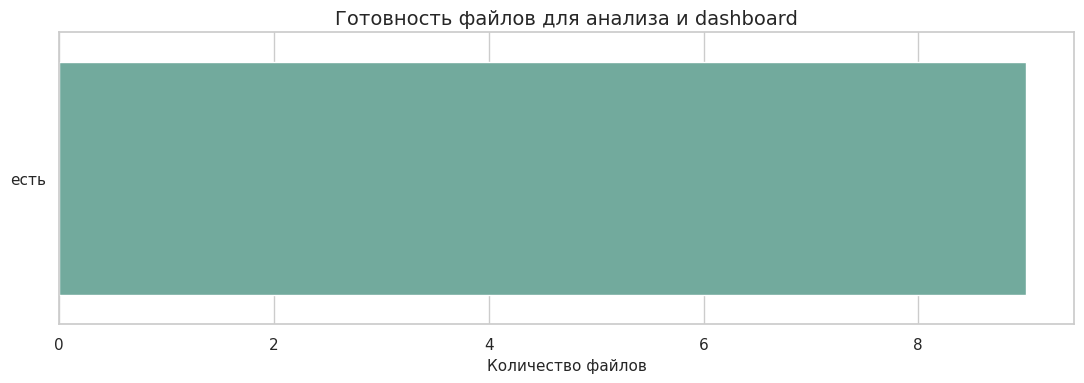

,артефакт,найден,размер_кб
0,comparison_metrics.csv,True,451.1
1,train_manifest.json,True,166.3
2,workload_metrics.csv,True,158.8
3,alert_level_metrics.csv,True,28.2
4,replay_bundle.csv.gz,True,1606.9
5,dashboard_model_report.json,True,13.5
6,latency_and_export_report.json,True,28.7
7,bundle/replay_bundle.csv.gz,True,1606.9
8,bundle/dashboard_model_report.json,True,13.5


In [6]:
expected = {
    "comparison_metrics.csv": RESULT_DIR / "comparison_metrics.csv",
    "train_manifest.json": RESULT_DIR / "train_manifest.json",
    "workload_metrics.csv": RESULT_DIR / "workload_metrics.csv",
    "alert_level_metrics.csv": RESULT_DIR / "alert_level_metrics.csv",
    "replay_bundle.csv.gz": RESULT_DIR / "replay_bundle.csv.gz",
    "dashboard_model_report.json": RESULT_DIR / "dashboard_model_report.json",
    "latency_and_export_report.json": RESULT_DIR / "latency_and_export_report.json",
    "bundle/replay_bundle.csv.gz": BUNDLE_DIR / "replay_bundle.csv.gz",
    "bundle/dashboard_model_report.json": BUNDLE_DIR / "dashboard_model_report.json",
}

status = file_status(expected)
plot_status = (
    status.assign(готов=status["найден"].map({True: "есть", False: "нет"}))
    .groupby("готов", as_index=False)
    .size()
    .rename(columns={"size": "файлов"})
)

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(
    data=plot_status,
    y="готов",
    x="файлов",
    hue="готов",
    palette={"есть": "#69b3a2", "нет": "#dd6b66"},
    legend=False,
    ax=ax,
)
ax.set_title("Готовность файлов для анализа и dashboard")
ax.set_xlabel("Количество файлов")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(status[["артефакт", "найден", "размер_кб"]])


Если здесь есть все ключевые файлы, дальше notebook уже не зависит от тяжелого обучения. Он читает сохраненные метрики, кривые, replay-bundle и строит исследовательскую часть. Если часть файлов отсутствует после переноса с другой машины, это место сразу покажет, чего не хватает, вместо того чтобы падать где-нибудь в середине анализа.


## Динамика обучения

Для финальной модели важно увидеть не только итоговую строку метрик. Если loss падает, а validation-метрики ведут себя хаотично, значит модель может ловить случайный checkpoint. Если же `val_ap`, `val_best_f1` и `val_fp_budget_f1` растут согласованно хотя бы на части эпох, картина становится спокойнее: модель действительно находит разделение в данных.


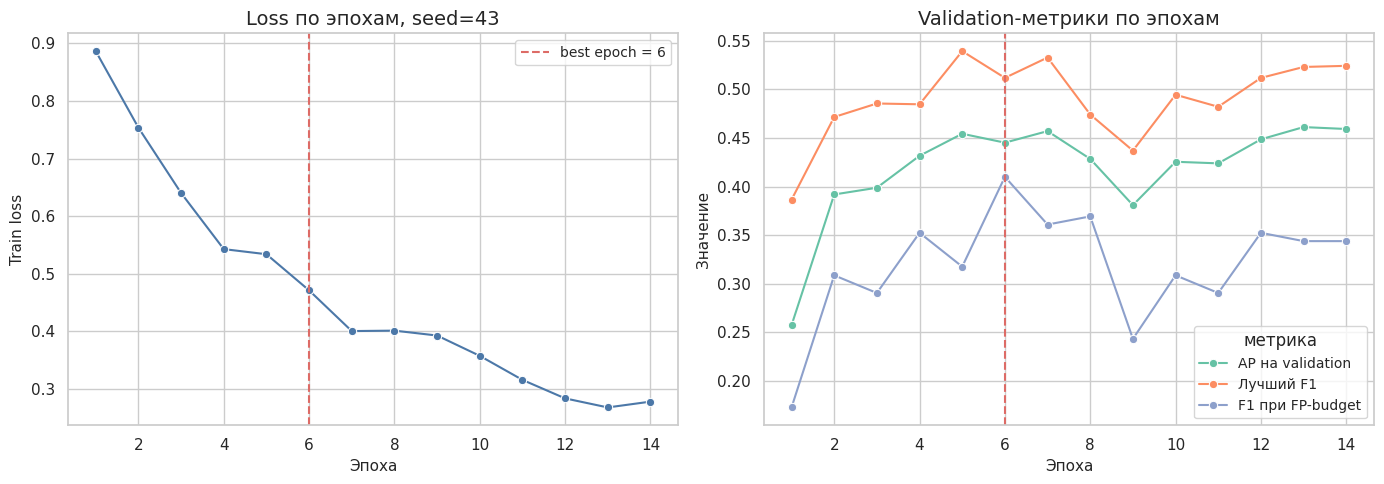

,split,вариант,seed,лучшая_эпоха,monitor
6,stratified_by_workload,modern_metric,42,3,0.352332
7,stratified_by_workload,modern_metric,43,6,0.410000
8,stratified_by_workload,modern_metric,44,12,0.485714


In [7]:
manifest = safe_read_json(RESULT_DIR / "train_manifest.json")
manifest_df = pd.DataFrame(manifest if isinstance(manifest, list) else [])

if manifest_df.empty:
    show_note("`train_manifest.json` не найден или пустой. После обучения здесь появятся кривые по эпохам.")
else:
    selected = manifest_df[
        manifest_df["split_protocol"].astype(str).eq(FINAL_CONFIG["split_protocol"])
        & manifest_df["variant"].astype(str).eq(FINAL_CONFIG["variant"])
    ].copy()

    history_rows = []
    for _, row in selected.iterrows():
        for rec in row.get("history", []) or []:
            history_rows.append(
                {
                    "seed": int(row["seed"]),
                    "best_epoch": int(row["best_epoch"]),
                    **rec,
                }
            )
    history_df = pd.DataFrame(history_rows)

    if history_df.empty:
        show_note("В manifest нет истории эпох для выбранной конфигурации.")
    else:
        seed_history = history_df[history_df["seed"].eq(FINAL_CONFIG["seed"])].copy()
        best_epoch = int(seed_history["best_epoch"].dropna().iloc[0]) if seed_history["best_epoch"].notna().any() else None

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.lineplot(data=seed_history, x="epoch", y="train_loss", marker="o", ax=axes[0], color="#4c78a8")
        axes[0].set_title(f"Loss по эпохам, seed={FINAL_CONFIG['seed']}")
        axes[0].set_xlabel("Эпоха")
        axes[0].set_ylabel("Train loss")
        if best_epoch:
            axes[0].axvline(best_epoch, ls="--", color="#dd6b66", label=f"best epoch = {best_epoch}")
            axes[0].legend()

        metric_cols = [c for c in ["val_ap", "val_best_f1", "val_fp_budget_f1"] if c in seed_history.columns]
        melted = seed_history.melt(id_vars=["epoch"], value_vars=metric_cols, var_name="метрика", value_name="значение")
        melted["метрика"] = melted["метрика"].map(
            {"val_ap": "AP на validation", "val_best_f1": "Лучший F1", "val_fp_budget_f1": "F1 при FP-budget"}
        )
        sns.lineplot(data=melted, x="epoch", y="значение", hue="метрика", marker="o", ax=axes[1])
        axes[1].set_title("Validation-метрики по эпохам")
        axes[1].set_xlabel("Эпоха")
        axes[1].set_ylabel("Значение")
        if best_epoch:
            axes[1].axvline(best_epoch, ls="--", color="#dd6b66")
        plt.tight_layout()
        plt.show()

        display(
            selected[["split_protocol", "variant", "seed", "best_epoch", "best_monitor"]]
            .sort_values("seed")
            .rename(
                columns={
                    "split_protocol": "split",
                    "variant": "вариант",
                    "seed": "seed",
                    "best_epoch": "лучшая_эпоха",
                    "best_monitor": "monitor",
                }
            )
        )


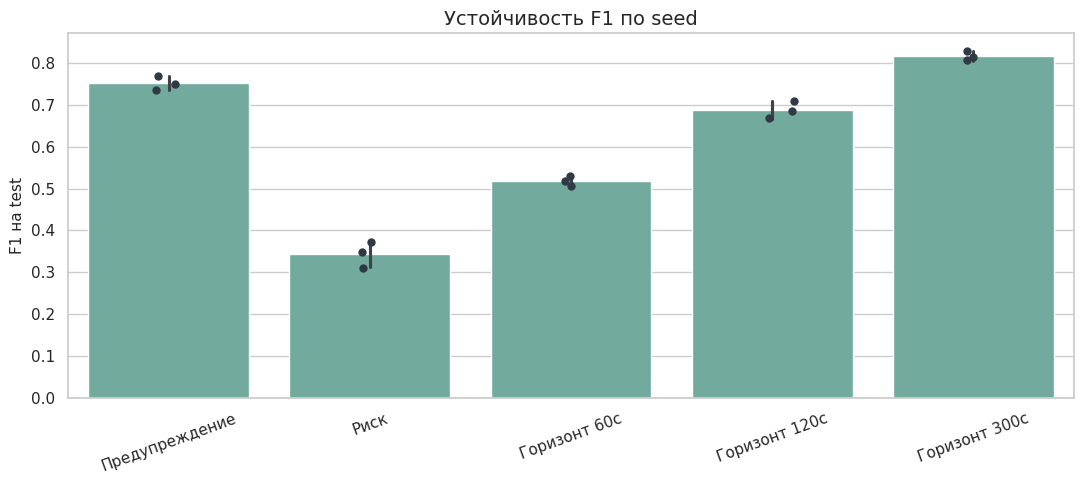

In [8]:
final_metrics_all = safe_read_csv(RESULT_DIR / "comparison_metrics.csv")
if final_metrics_all.empty:
    show_note("`comparison_metrics.csv` пока отсутствует.")
else:
    tmp = final_metrics_all.copy()
    for col in ["seed", "f1", "precision", "recall", "average_precision"]:
        if col in tmp.columns:
            tmp[col] = pd.to_numeric(tmp[col], errors="coerce")
    stability = tmp[
        tmp["split_protocol"].astype(str).eq(FINAL_CONFIG["split_protocol"])
        & tmp["variant"].astype(str).eq(FINAL_CONFIG["variant"])
        & tmp["runtime"].astype(str).eq("torch_fp32")
        & tmp["split"].astype(str).eq("test")
        & tmp["threshold_policy"].astype(str).eq("validation_best_f1")
        & tmp["target"].isin(["horizon_60s", "horizon_120s", "horizon_300s", "y_warning", "y_risk"])
    ].copy()

    if stability.empty:
        show_note("Нет данных для оценки устойчивости по seed.")
    else:
        stability["target_label"] = stability["target"].map(TARGET_LABELS)
        fig, ax = plt.subplots(figsize=(11, 5))
        sns.barplot(data=stability, x="target_label", y="f1", errorbar="sd", ax=ax, color="#69b3a2")
        sns.stripplot(data=stability, x="target_label", y="f1", ax=ax, color="#2f3a45", size=6, jitter=0.12)
        ax.set_title("Устойчивость F1 по seed")
        ax.set_xlabel("")
        ax.set_ylabel("F1 на test")
        ax.tick_params(axis="x", rotation=20)
        plt.tight_layout()
        plt.show()


Здесь есть два нормальных признака здорового обучения. Во-первых, кривые не должны требовать ручного выбора “любимой” эпохи по памяти: best epoch берется из manifest. Во-вторых, разброс по seed не обязан исчезнуть полностью, но он должен быть виден и измерим. Для такой задачи небольшой разброс ожидаем: окна короткие, targets разной плотности, а `horizon_60s` сам по себе шумный.


## Качество финальной модели

Теперь смотрим на test. Здесь главный акцент не на одной “магической” метрике, а на связке `Precision / Recall / F1`. Для early-warning высокая полнота полезна только до тех пор, пока она не превращает систему в постоянный шум. Поэтому рядом с F1 обязательно смотрим число false positives и missed anomalies.


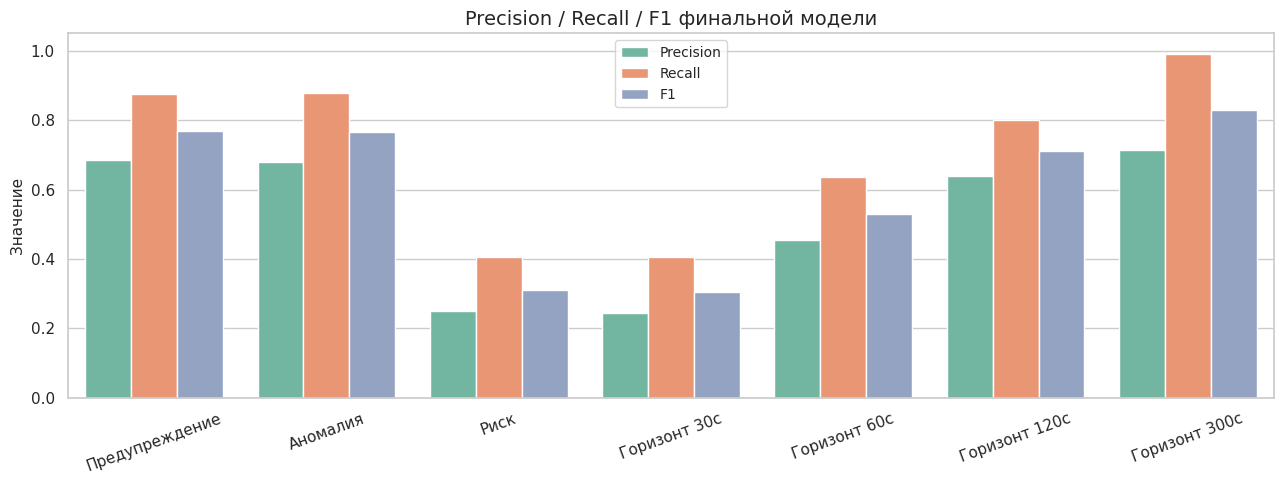

,target,precision,recall,f1,average_precision,roc_auc,false_positives,missed_anomalies
210,Предупреждение,0.685,0.875,0.768,0.788,0.768,116,36
212,Риск,0.250,0.407,0.310,0.280,0.763,72,35
214,Аномалия,0.678,0.878,0.766,0.782,0.763,120,35
216,Горизонт 30с,0.245,0.407,0.306,0.280,0.765,74,35
218,Горизонт 60с,0.455,0.637,0.531,0.490,0.742,103,49
220,Горизонт 120с,0.638,0.801,0.710,0.703,0.756,105,46
222,Горизонт 300с,0.713,0.991,0.829,0.835,0.768,129,3


In [9]:
final_metrics = safe_read_csv(RESULT_DIR / "comparison_metrics.csv")
final_test = filter_final_metrics(final_metrics, "validation_best_f1")

if final_test.empty:
    show_note("Итоговые test-метрики пока не найдены. После CUDA-запуска здесь появится сводка финальной модели.")
else:
    final_test["target_label"] = pd.Categorical(
        final_test["target"].map(TARGET_LABELS),
        categories=[TARGET_LABELS[t] for t in TARGET_ORDER if t in final_test["target"].unique()],
        ordered=True,
    )
    plot_df = final_test.melt(
        id_vars=["target", "target_label"],
        value_vars=["precision", "recall", "f1"],
        var_name="метрика",
        value_name="значение",
    )
    plot_df["метрика"] = plot_df["метрика"].map(METRIC_LABELS)

    fig, ax = plt.subplots(figsize=(13, 5))
    sns.barplot(data=plot_df, x="target_label", y="значение", hue="метрика", ax=ax)
    ax.set_title("Precision / Recall / F1 финальной модели")
    ax.set_xlabel("")
    ax.set_ylabel("Значение")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="")
    plt.tight_layout()
    plt.show()

    compact = final_test[
        [
            "target",
            "precision",
            "recall",
            "f1",
            "average_precision",
            "roc_auc",
            "false_positives",
            "missed_anomalies",
        ]
    ].copy()
    compact["target"] = compact["target"].map(TARGET_LABELS)
    display(compact.round(3))


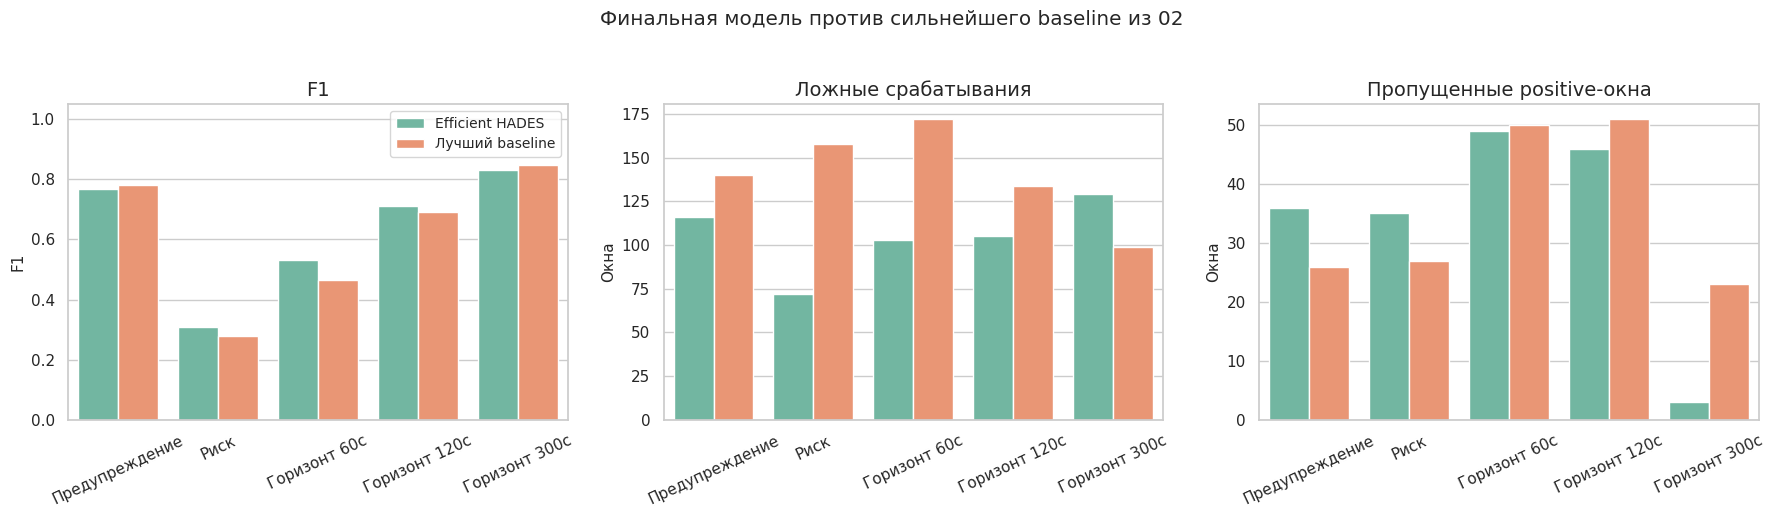

,target,baseline,f1_final,f1_baseline,delta_f1,delta_precision,delta_recall
4,Горизонт 60с,fused_log_metric,0.531,0.466,0.065,0.094,-0.023
1,Риск,fused_log_metric,0.310,0.280,0.030,0.064,-0.165
3,Горизонт 30с,fused_log_metric,0.306,0.280,0.026,0.059,-0.165
5,Горизонт 120с,fused_log_metric,0.710,0.692,0.018,0.030,-0.002
0,Предупреждение,log_tfidf,0.768,0.780,-0.012,0.007,-0.044
2,Аномалия,log_tfidf,0.766,0.780,-0.014,0.001,-0.040
6,Горизонт 300с,metric_raw,0.829,0.846,-0.017,-0.059,0.055


In [10]:
baseline_metrics = safe_read_csv(BASELINE_DIR / "baseline_protocol_metrics.csv")
baseline_best = best_baseline_metrics(baseline_metrics, "validation_best_f1")

if final_test.empty or baseline_best.empty:
    show_note("Для сравнения нужны и финальные метрики, и baseline из 02.")
else:
    final_view = final_test[
        ["target", "precision", "recall", "f1", "average_precision", "roc_auc", "false_positives", "missed_anomalies"]
    ].copy()
    final_view["model"] = "Efficient HADES"
    base_view = baseline_best[
        ["target", "precision", "recall", "f1", "average_precision", "roc_auc", "false_positives", "missed_anomalies", "baseline"]
    ].copy()
    base_view["model"] = "Лучший baseline"

    joined = pd.concat([final_view, base_view], ignore_index=True, sort=False)
    joined = joined[joined["target"].isin(["y_warning", "y_risk", "horizon_60s", "horizon_120s", "horizon_300s"])].copy()
    joined["target_label"] = joined["target"].map(TARGET_LABELS)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)
    sns.barplot(data=joined, x="target_label", y="f1", hue="model", ax=axes[0])
    axes[0].set_title("F1")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("F1")
    axes[0].set_ylim(0, 1.05)
    axes[0].tick_params(axis="x", rotation=25)

    sns.barplot(data=joined, x="target_label", y="false_positives", hue="model", ax=axes[1])
    axes[1].set_title("Ложные срабатывания")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Окна")
    axes[1].tick_params(axis="x", rotation=25)

    sns.barplot(data=joined, x="target_label", y="missed_anomalies", hue="model", ax=axes[2])
    axes[2].set_title("Пропущенные positive-окна")
    axes[2].set_xlabel("")
    axes[2].set_ylabel("Окна")
    axes[2].tick_params(axis="x", rotation=25)

    for ax in axes[1:]:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    axes[0].legend(title="")
    plt.suptitle("Финальная модель против сильнейшего baseline из 02", y=1.03)
    plt.tight_layout()
    plt.show()

    delta = final_view.merge(
        base_view[["target", "baseline", "f1", "precision", "recall"]],
        on="target",
        suffixes=("_final", "_baseline"),
        how="inner",
    )
    delta["target"] = delta["target"].map(TARGET_LABELS)
    delta["delta_f1"] = delta["f1_final"] - delta["f1_baseline"]
    delta["delta_precision"] = delta["precision_final"] - delta["precision_baseline"]
    delta["delta_recall"] = delta["recall_final"] - delta["recall_baseline"]
    display(
        delta[
            [
                "target",
                "baseline",
                "f1_final",
                "f1_baseline",
                "delta_f1",
                "delta_precision",
                "delta_recall",
            ]
        ]
        .sort_values("delta_f1", ascending=False)
        .round(3)
    )


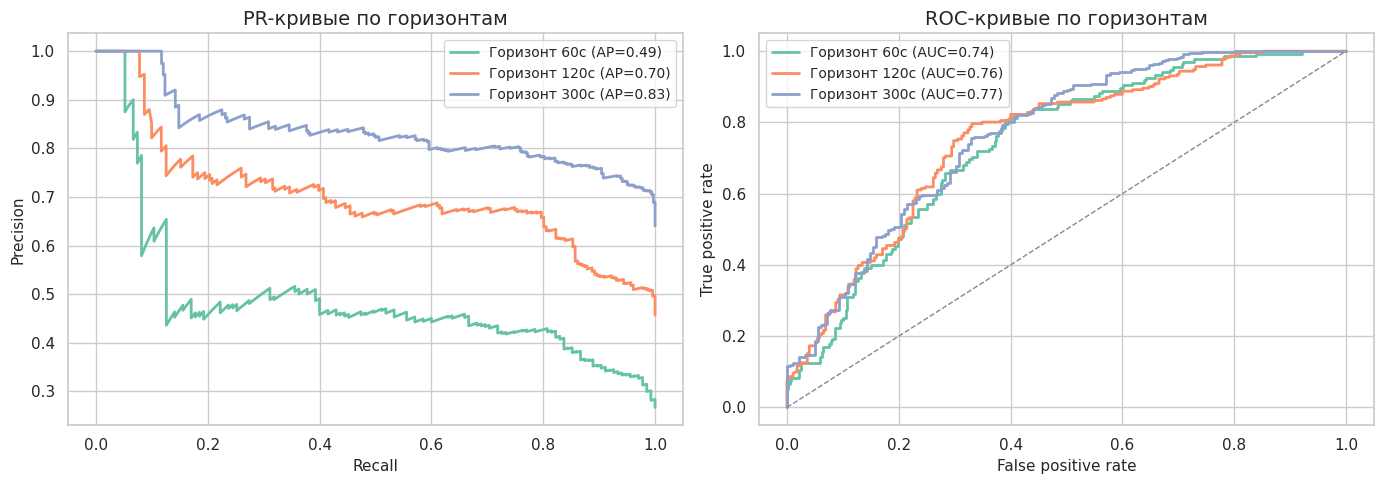

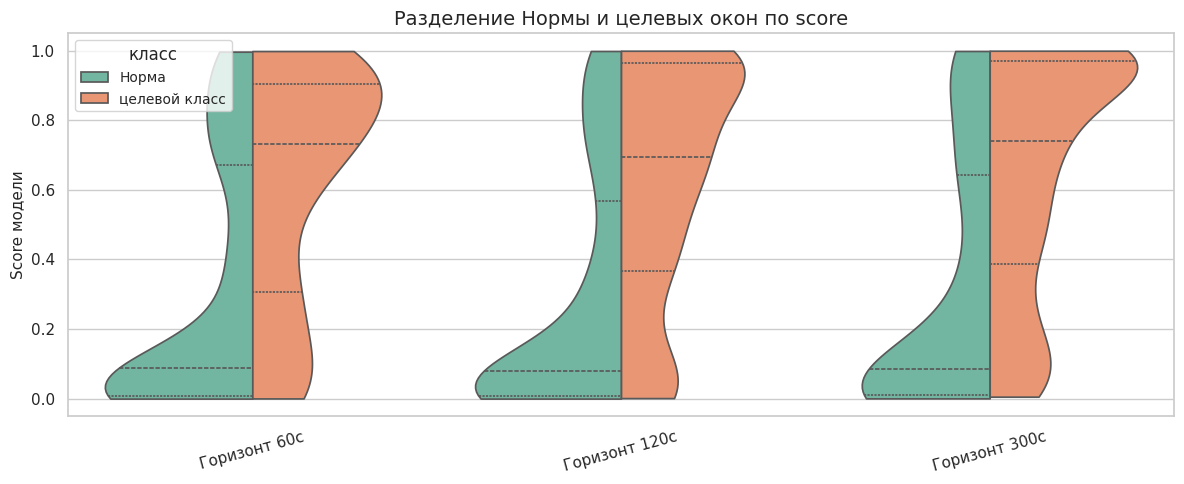

In [11]:
replay = safe_read_csv(RESULT_DIR / "replay_bundle.csv.gz")

if replay.empty:
    show_note("`replay_bundle.csv.gz` не найден. PR/ROC-кривые появятся после экспорта bundle.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    targets_for_curves = ["horizon_60s", "horizon_120s", "horizon_300s"]
    for target in targets_for_curves:
        y_col = f"target_{target}"
        s_col = f"score_{target}"
        if y_col not in replay.columns or s_col not in replay.columns:
            continue
        y = pd.to_numeric(replay[y_col], errors="coerce").fillna(0).astype(int).to_numpy()
        score = pd.to_numeric(replay[s_col], errors="coerce").fillna(0).to_numpy()
        if len(np.unique(y)) < 2:
            continue
        precision, recall, _ = precision_recall_curve(y, score)
        fpr, tpr, _ = roc_curve(y, score)
        axes[0].plot(recall, precision, lw=2, label=f"{TARGET_LABELS[target]} (AP={auc(recall, precision):.2f})")
        axes[1].plot(fpr, tpr, lw=2, label=f"{TARGET_LABELS[target]} (AUC={auc(fpr, tpr):.2f})")

    axes[0].set_title("PR-кривые по горизонтам")
    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].legend()
    axes[1].plot([0, 1], [0, 1], ls="--", color="#888", lw=1)
    axes[1].set_title("ROC-кривые по горизонтам")
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    score_rows = []
    for target in targets_for_curves:
        y_col = f"target_{target}"
        s_col = f"score_{target}"
        if y_col in replay.columns and s_col in replay.columns:
            temp = replay[[y_col, s_col]].copy()
            temp["target"] = TARGET_LABELS[target]
            temp["класс"] = np.where(pd.to_numeric(temp[y_col], errors="coerce").fillna(0).astype(int) == 1, "целевой класс", "Норма")
            temp["score"] = pd.to_numeric(temp[s_col], errors="coerce")
            score_rows.append(temp[["target", "класс", "score"]])
    if score_rows:
        score_df = pd.concat(score_rows, ignore_index=True)
        fig, ax = plt.subplots(figsize=(12, 5))
        sns.violinplot(data=score_df, x="target", y="score", hue="класс", split=True, inner="quartile", cut=0, ax=ax)
        ax.set_title("Разделение Нормы и целевых окон по score")
        ax.set_xlabel("")
        ax.set_ylabel("Score модели")
        ax.tick_params(axis="x", rotation=15)
        plt.tight_layout()
        plt.show()


Кривые здесь нужны не “для красоты”. Они отвечают на вопрос, есть ли у score запас для настройки порогов. Если PR-кривая быстро падает, то простой перенос threshold не спасет задачу. Если распределения normal/positive заметно расходятся, alert-layer может аккуратно выбирать компромисс между пропусками и шумом.


## Ошибки модели

Window-level метрики полезны, но они слишком легко прячут живую картину. В dashboard пользователь будет видеть конкретные окна: где модель подняла score, где промолчала, на каком workload это произошло. Поэтому отдельно смотрим FP/FN для основного `horizon_60s`.


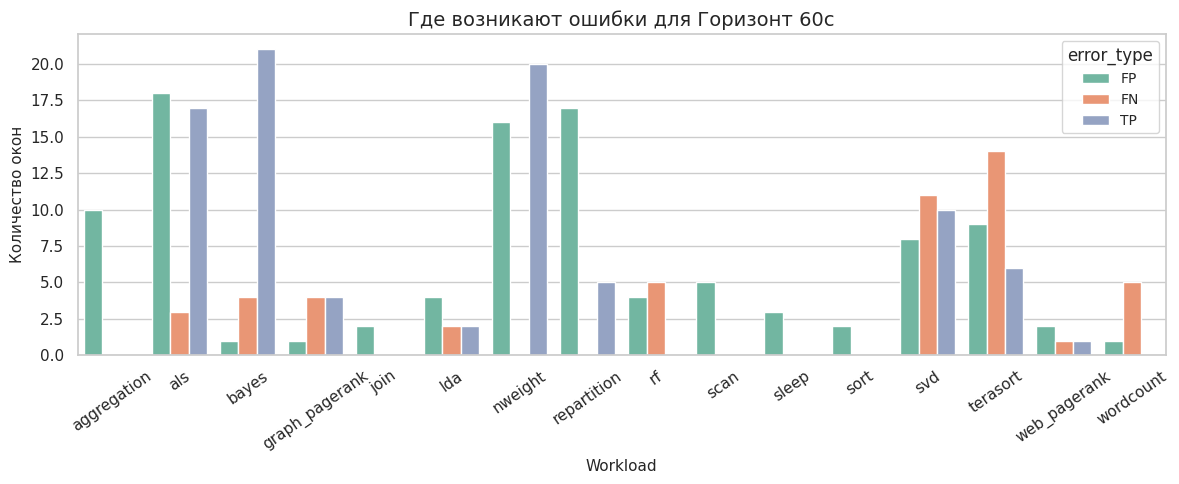

,error_type,workload,run_id,window_ts,state,target_value,score,alert_state
0,FP,aggregation,aggregation/normal6,2021-10-20 12:58:00+00:00,normal,0,0.9972,alert
1,FP,nweight,nweight/nodemanager_suspended,2021-10-19 09:35:40+00:00,warning,0,0.9964,alert
2,FP,nweight,nweight/master_suspended,2021-10-19 12:05:50+00:00,warning,0,0.9937,alert
3,FP,aggregation,aggregation/normal6,2021-10-20 12:57:50+00:00,normal,0,0.9929,alert
4,FP,aggregation,aggregation/normal6,2021-10-20 12:57:30+00:00,normal,0,0.9914,alert
5,FP,nweight,nweight/nodemanager_suspended,2021-10-19 09:35:30+00:00,warning,0,0.9909,alert
6,FN,wordcount,wordcount/master_killed,2021-10-15 05:35:40+00:00,warning,1,0.0006,watch
7,FN,terasort,terasort/cpu_stress,2021-10-15 11:35:50+00:00,warning,1,0.0034,watch
8,FN,rf,rf/datanode_killed,2021-10-25 04:50:40+00:00,risk,1,0.0057,normal
9,FN,terasort,terasort/cpu_stress,2021-10-15 11:36:00+00:00,warning,1,0.0088,watch


In [12]:
if replay.empty or final_test.empty:
    show_note("Для анализа ошибок нужны replay_bundle и итоговые thresholds.")
else:
    target = FINAL_CONFIG["monitor_target"]
    y_col = f"target_{target}"
    s_col = f"score_{target}"
    threshold_row = final_test[final_test["target"].eq(target)]
    if y_col not in replay.columns or s_col not in replay.columns or threshold_row.empty:
        show_note(f"Нет нужных колонок для {target}.")
    else:
        threshold = float(threshold_row["threshold"].iloc[0])
        err_df = replay.copy()
        err_df["target_value"] = pd.to_numeric(err_df[y_col], errors="coerce").fillna(0).astype(int)
        err_df["score_value"] = pd.to_numeric(err_df[s_col], errors="coerce").fillna(0)
        err_df["predicted"] = (err_df["score_value"] >= threshold).astype(int)
        err_df["error_type"] = np.select(
            [
                (err_df["target_value"].eq(0) & err_df["predicted"].eq(1)),
                (err_df["target_value"].eq(1) & err_df["predicted"].eq(0)),
                (err_df["target_value"].eq(1) & err_df["predicted"].eq(1)),
                (err_df["target_value"].eq(0) & err_df["predicted"].eq(0)),
            ],
            ["FP", "FN", "TP", "TN"],
            default="unknown",
        )

        breakdown = (
            err_df.groupby(["workload", "error_type"])
            .size()
            .rename("окна")
            .reset_index()
        )
        focus_breakdown = breakdown[breakdown["error_type"].isin(["FP", "FN", "TP"])].copy()

        fig, ax = plt.subplots(figsize=(12, 5))
        sns.barplot(data=focus_breakdown, x="workload", y="окна", hue="error_type", ax=ax)
        ax.set_title(f"Где возникают ошибки для {TARGET_LABELS[target]}")
        ax.set_xlabel("Workload")
        ax.set_ylabel("Количество окон")
        ax.tick_params(axis="x", rotation=35)
        plt.tight_layout()
        plt.show()

        fp_examples = (
            err_df[err_df["error_type"].eq("FP")]
            .sort_values("score_value", ascending=False)
            .head(6)
        )
        fn_examples = (
            err_df[err_df["error_type"].eq("FN")]
            .sort_values("score_value", ascending=True)
            .head(6)
        )
        examples = pd.concat([fp_examples, fn_examples], ignore_index=True)
        cols = [c for c in ["error_type", "workload", "run_id", "window_ts", "state", "target_value", "score_value", "alert_state"] if c in examples.columns]
        display(examples[cols].rename(columns={"score_value": "score"}).round(4))


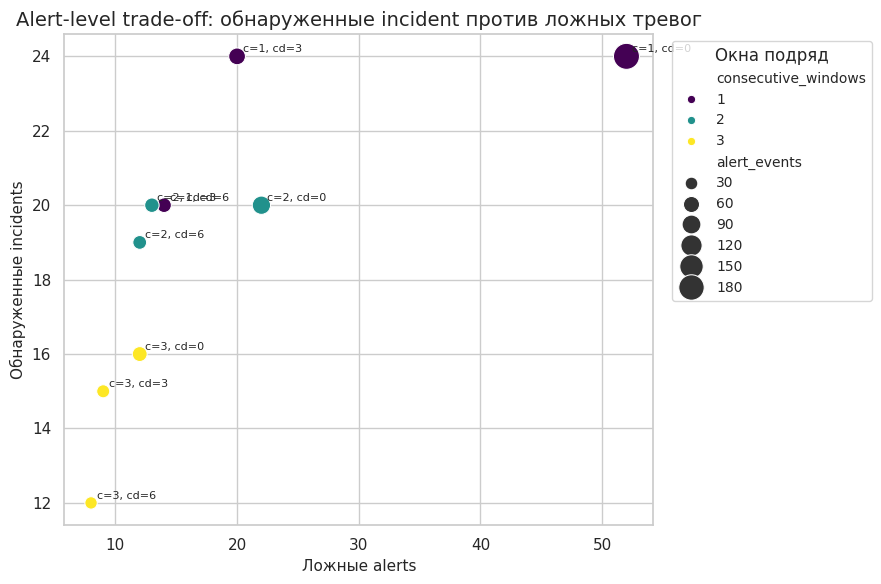

,окон_подряд,cooldown,alerts,ложные_alerts,найдено_incidents,пропущено_incidents
307,1,3,67,20,24,5
306,1,0,189,52,24,5
310,2,3,45,13,20,9
308,1,6,46,14,20,9
309,2,0,84,22,20,9


In [13]:
alert = safe_read_csv(RESULT_DIR / "alert_level_metrics.csv")

if alert.empty:
    show_note("`alert_level_metrics.csv` не найден. После экспорта появится оценка alert-layer.")
else:
    alert_sel = alert[
        alert["split_protocol"].astype(str).eq(FINAL_CONFIG["split_protocol"])
        & alert["variant"].astype(str).eq(FINAL_CONFIG["variant"])
        & pd.to_numeric(alert["seed"], errors="coerce").eq(FINAL_CONFIG["seed"])
        & alert["target"].astype(str).eq(FINAL_CONFIG["alert_target"])
    ].copy()
    for col in ["false_alerts", "detected_incidents", "missed_incidents", "alert_events", "consecutive_windows", "cooldown_windows"]:
        if col in alert_sel.columns:
            alert_sel[col] = pd.to_numeric(alert_sel[col], errors="coerce")

    if alert_sel.empty:
        show_note("Нет alert-level строк для выбранного target.")
    else:
        fig, ax = plt.subplots(figsize=(9, 6))
        sns.scatterplot(
            data=alert_sel,
            x="false_alerts",
            y="detected_incidents",
            size="alert_events",
            hue="consecutive_windows",
            palette="viridis",
            sizes=(80, 350),
            ax=ax,
        )
        for _, row in alert_sel.iterrows():
            ax.annotate(
                f"c={int(row['consecutive_windows'])}, cd={int(row['cooldown_windows'])}",
                (row["false_alerts"], row["detected_incidents"]),
                fontsize=8,
                xytext=(4, 3),
                textcoords="offset points",
            )
        ax.set_title("Alert-level trade-off: обнаруженные incident против ложных тревог")
        ax.set_xlabel("Ложные alerts")
        ax.set_ylabel("Обнаруженные incidents")
        ax.legend(title="Окна подряд", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

        recommended = alert_sel.sort_values(["detected_incidents", "false_alerts"], ascending=[False, True]).head(5)
        display(
            recommended[
                [
                    "consecutive_windows",
                    "cooldown_windows",
                    "alert_events",
                    "false_alerts",
                    "detected_incidents",
                    "missed_incidents",
                ]
            ].rename(
                columns={
                    "consecutive_windows": "окон_подряд",
                    "cooldown_windows": "cooldown",
                    "alert_events": "alerts",
                    "false_alerts": "ложные_alerts",
                    "detected_incidents": "найдено_incidents",
                    "missed_incidents": "пропущено_incidents",
                }
            )
        )


Здесь хорошо видно, почему в системе нельзя смешивать `score модели`, `alert_state` и `incident`. Score считается для каждого окна. Alert-layer добавляет правило устойчивости: например, требовать несколько окон подряд или cooldown после тревоги. Это снижает шум, но платит пропущенными incident. Именно этот компромисс и должен быть показан в dashboard, а не спрятан внутри одной цифры F1.


## Готовность к dashboard и runtime

Последняя проверка уже не про качество модели, а про переносимость. Dashboard не должен переобучать модель и не должен догадываться, где лежат thresholds. Он читает bundle: replay, report, alert-events, baseline-comparison и model-card. ONNX/INT8 оставлены как runtime-слоты для слабых CPU-систем, но они не заменяют основную оценку качества.


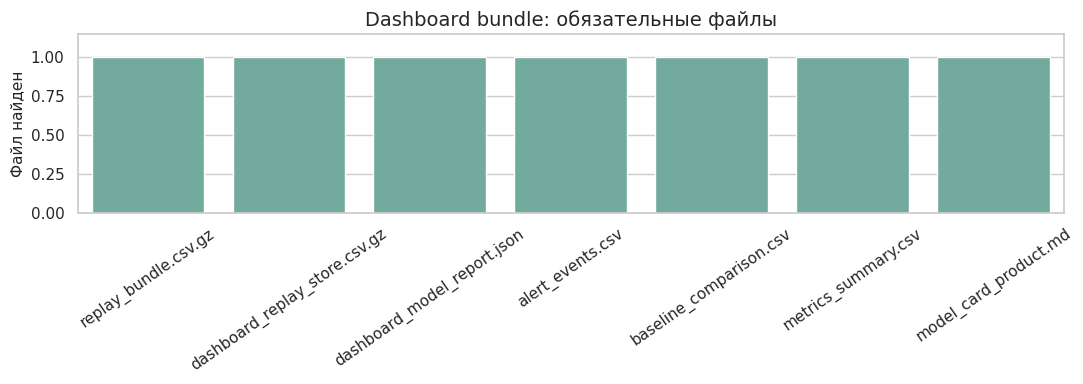

,артефакт,найден,размер_кб
0,replay_bundle.csv.gz,True,1606.9
1,dashboard_replay_store.csv.gz,True,1606.9
2,dashboard_model_report.json,True,13.5
3,alert_events.csv,True,5.7
4,baseline_comparison.csv,True,1.8
5,metrics_summary.csv,True,0.3
6,model_card_product.md,True,1.8


,runtime,status,path
0,torch_state,missing_checkpoint_copy_required,dashboard\artifacts\model\protocol_fixed_effic...
1,onnx_fp32,reserved_not_exported,dashboard\artifacts\model\protocol_fixed_effic...
2,onnx_int8,reserved_not_quantized,dashboard\artifacts\model\protocol_fixed_effic...


In [14]:
report = safe_read_json(RESULT_DIR / "dashboard_model_report.json") or safe_read_json(BUNDLE_DIR / "dashboard_model_report.json")
bundle_status = file_status(
    {
        "replay_bundle.csv.gz": BUNDLE_DIR / "replay_bundle.csv.gz",
        "dashboard_replay_store.csv.gz": BUNDLE_DIR / "dashboard_replay_store.csv.gz",
        "dashboard_model_report.json": BUNDLE_DIR / "dashboard_model_report.json",
        "alert_events.csv": BUNDLE_DIR / "alert_events.csv",
        "baseline_comparison.csv": BUNDLE_DIR / "baseline_comparison.csv",
        "metrics_summary.csv": BUNDLE_DIR / "metrics_summary.csv",
        "model_card_product.md": BUNDLE_DIR / "model_card_product.md",
    }
)

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=bundle_status, x="артефакт", y="найден", ax=ax, color="#69b3a2")
ax.set_title("Dashboard bundle: обязательные файлы")
ax.set_xlabel("")
ax.set_ylabel("Файл найден")
ax.set_ylim(0, 1.15)
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

display(bundle_status[["артефакт", "найден", "размер_кб"]])

if isinstance(report, dict):
    runtime = report.get("runtime", {})
    runtime_rows = []
    for slot in ["torch_state", "onnx_fp32", "onnx_int8"]:
        value = runtime.get(slot, {})
        runtime_rows.append(
            {
                "runtime": slot,
                "status": value.get("status", "not_recorded") if isinstance(value, dict) else "not_recorded",
                "path": value.get("path", "") if isinstance(value, dict) else "",
            }
        )
    display(pd.DataFrame(runtime_rows))
else:
    show_note("dashboard_model_report.json пока отсутствует или пустой.")


## Ограничения, которые нужно честно оставить в тексте ВКР

Финальная модель не превращает задачу в идеальный бинарный оракул. На длинном горизонте `horizon_300s` простой metric-baseline может быть очень сильным, потому что сигнал уже достаточно близко к событию и хорошо виден в KPI. На коротких горизонтах модель выигрывает не за счет магии, а за счет более богатого совместного представления: она видит и логовую последовательность, и динамику KPI, и учит несколько heads одновременно.

В практической системе это означает три вещи:

- основной вывод надо делать не по одной строке F1, а по `Precision / Recall / F1` и числу FP/FN;
- `horizon_60s` полезен как ранний, но шумный канал, поэтому его обязательно пропускать через alert-layer;
- ONNX/INT8 стоит рассматривать как runtime-ускорение для CPU-only стенда, а не как отдельную “лучшую модель”.

## Итог 03

В этом ноутбуке финальная Efficient HADES модель оформлена как единый исследовательский и прикладной контур. Мы не просто запускаем training-script: сначала фиксируем архитектурную роль модели, затем проверяем динамику обучения, сравниваем ее с baseline из 02, разбираем ошибки на окнах и переводим результат в alert-level, который уже можно показывать в dashboard.

Главный смысл этого слоя такой: baseline доказал, что данные и протокол работоспособны; финальная модель собирает этот протокол в один мультимодальный механизм раннего предупреждения. Для демонстрации системы это важнее, чем гонка за одной максимальной цифрой в таблице.
